<figure><center>
<img src='https://www.economicas.uba.ar/wp-content/uploads/2020/08/cropped-logo_FCE.png''/>
</center></figure>

# Creación de Datasets Sintéticos

Un dataset sintético es uno generado artificialmente, no obtenido de una fuente real. Se usa para:
- Practicar análisis sin depender de datos reales
- Probar código con datos controlados
- Generar datos de examen con variaciones por alumno

En esta notebook vemos cómo usar `numpy` para generar distintos tipos de datos al azar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## 1. Semilla aleatoria — `np.random.seed()`

Los números "al azar" de numpy no son verdaderamente aleatorios: son generados por un algoritmo determinista a partir de un número inicial llamado **semilla**.

Si dos personas usan la misma semilla, obtienen exactamente los mismos números.

In [2]:
# Sin semilla: cada ejecución da números distintos
print(np.random.randint(0, 100, 5))
print(np.random.randint(0, 100, 5))

[65 56 35 40 70]
[30 66 40 57 68]


In [3]:
# Con semilla: siempre el mismo resultado
np.random.seed(42)
print(np.random.randint(0, 100, 5))

np.random.seed(42)   # reseteamos la semilla
print(np.random.randint(0, 100, 5))  # mismo resultado

[51 92 14 71 60]
[51 92 14 71 60]


In [4]:
# Uso típico en exámenes: cada alumno usa su número de matrícula como semilla
# Así todos tienen datos distintos pero reproducibles
matricula = 100234
np.random.seed(matricula)
print(np.random.randint(0, 100, 5))

[56 51 91 57 52]


---
## 2. Enteros uniformes — `np.random.randint()`

Genera enteros entre `low` (inclusive) y `high` (exclusive).

In [5]:
np.random.seed(42)

# Cantidades vendidas por producto
productos = ['Notebook', 'Celular', 'Tablet', 'Auriculares', 'Monitor']
cantidades = np.random.randint(1, 51, size=len(productos))

for p, c in zip(productos, cantidades):
    print(f"{p}: {c} unidades")

Notebook: 39 unidades
Celular: 29 unidades
Tablet: 15 unidades
Auriculares: 43 unidades
Monitor: 8 unidades


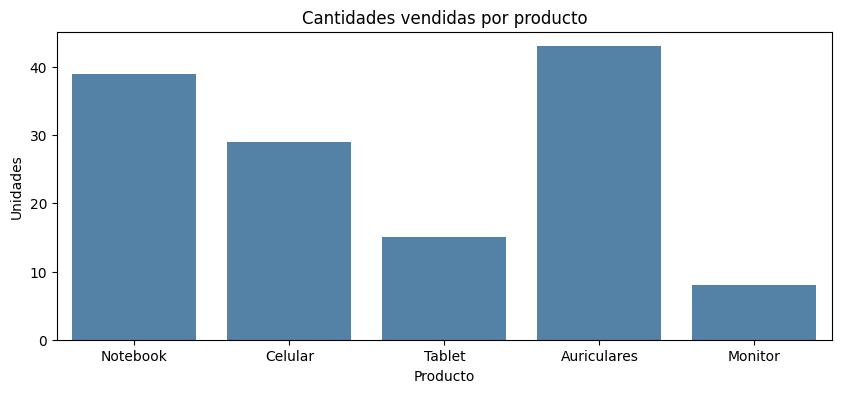

In [22]:
plt.figure(figsize=(10, 4)) 
sns.barplot(x=productos, y=cantidades, color='steelblue')
plt.title('Cantidades vendidas por producto')
plt.xlabel('Producto')
plt.ylabel('Unidades')
plt.show()

---
## 3. Floats uniformes — `np.random.uniform()`

Genera números decimales distribuidos uniformemente entre `low` y `high`.
Todos los valores tienen la misma probabilidad de aparecer.

In [7]:
np.random.seed(42)

# Precios entre $500 y $15000
precios = np.random.uniform(500, 15000, size=200).round(2)
print(f"Mínimo: ${precios.min():,.0f}")
print(f"Máximo: ${precios.max():,.0f}")
print(f"Media:  ${precios.mean():,.0f}")

Mínimo: $580
Máximo: $14,810
Media:  $7,518


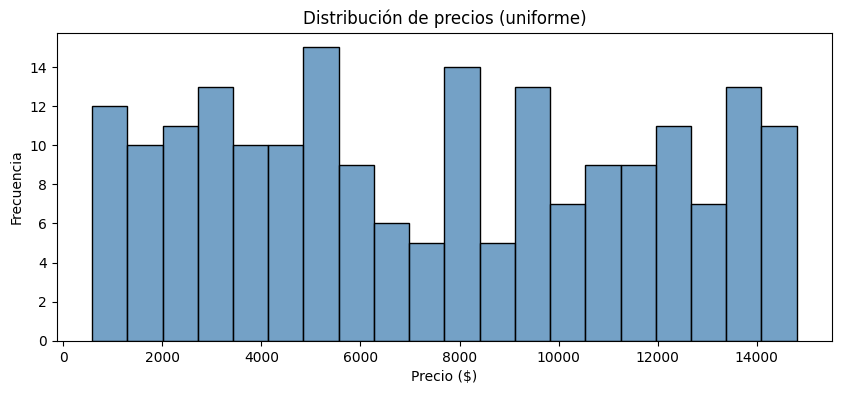

In [25]:
# La distribución uniforme genera una frecuencia pareja en todo el rango
plt.figure(figsize=(10, 4)) 
sns.histplot(precios, bins=20, color='steelblue')
plt.title('Distribución de precios (uniforme)')
plt.xlabel('Precio ($)')
plt.ylabel('Frecuencia')
plt.show()

---
## 4. Distribución normal — `np.random.normal()`

Genera números con distribución normal (campana de Gauss). Requiere:
- `loc`: media (µ) — centro de la distribución
- `scale`: desvío estándar (σ) — qué tan dispersos están los valores

In [9]:
np.random.seed(42)

# Salarios con media $150.000 y desvío $20.000
salarios = np.random.normal(loc=150000, scale=20000, size=200)
print(f"Media real:  ${salarios.mean():,.0f}")
print(f"Desvío real: ${salarios.std():,.0f}")

Media real:  $149,185
Desvío real: $18,573


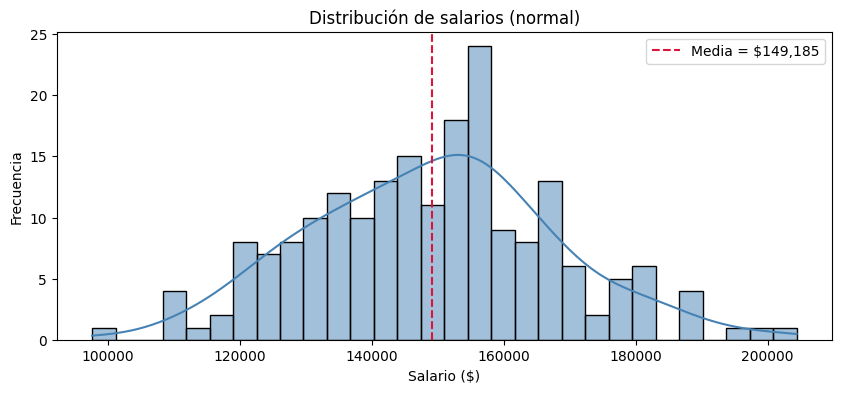

In [12]:
# kde=True superpone la curva de densidad estimada
plt.figure(figsize=(10, 4))   # ancho x alto en pulgadas
sns.histplot(salarios, bins=30, color='steelblue', kde=True)
plt.axvline(salarios.mean(), color='crimson', linestyle='--', label=f'Media = ${salarios.mean():,.0f}')
plt.title('Distribución de salarios (normal)')
plt.xlabel('Salario ($)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

In [13]:
# np.clip limita los valores a un rango — útil para notas entre 0 y 10
notas_raw = np.random.normal(loc=6, scale=1.5, size=50)
notas = np.clip(notas_raw, 0, 10).round(1)
print("Notas:", notas)

Notas: [ 6.5  6.8  7.6  7.6  3.9  4.6  6.8  6.8  6.8 10.   6.9  7.7  7.4  7.
  5.5  7.1  4.8  5.6  5.3  6.1  9.5  3.2  7.   3.6  5.3  7.6  6.1  4.4
  4.9  7.   4.9  6.3  6.1  5.   9.2  7.   3.   6.3  5.   7.3  4.8  5.8
  6.8  7.3  4.2  5.5  5.3  5.   8.6  6.6]


---
## 5. Elegir de una lista — `np.random.choice()`

Elige elementos al azar de un array o lista. Útil para columnas categóricas.

In [14]:
np.random.seed(42)

categorias = ['Electrónica', 'Ropa', 'Alimentos', 'Hogar']

# Sin probabilidades: cada categoría tiene la misma chance
col_cat = np.random.choice(categorias, size=100)

# Con probabilidades: Alimentos aparece más seguido
probs = [0.15, 0.20, 0.45, 0.20]   # deben sumar 1
col_cat_sesgada = np.random.choice(categorias, size=100, p=probs)

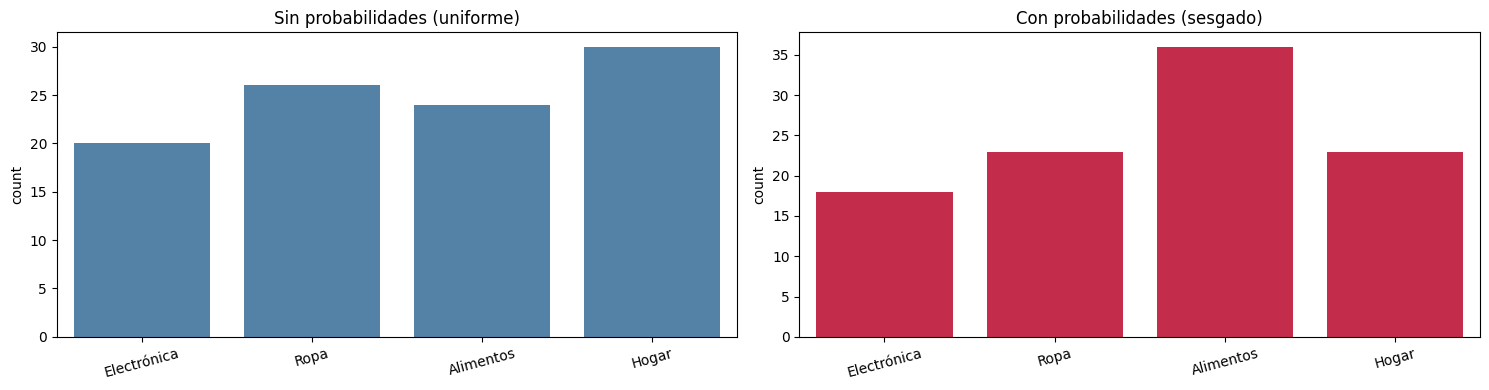

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

sns.countplot(x=col_cat, order=categorias, color='steelblue', ax=axes[0])
axes[0].set_title('Sin probabilidades (uniforme)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=15)

sns.countplot(x=col_cat_sesgada, order=categorias, color='crimson', ax=axes[1])
axes[1].set_title('Con probabilidades (sesgado)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

---
## 6. Mezclar — `shuffle` y `permutation`

- `np.random.shuffle()` mezcla **en el lugar** (modifica el array original)
- `np.random.permutation()` devuelve una copia mezclada (no modifica el original)

In [16]:
np.random.seed(42)

ids = np.arange(1, 11)
print("Original:", ids)

# shuffle modifica el array directamente
np.random.shuffle(ids)
print("Después de shuffle:", ids)

Original: [ 1  2  3  4  5  6  7  8  9 10]
Después de shuffle: [ 9  2  6  1  8  3 10  5  4  7]


In [17]:
np.random.seed(42)

ids = np.arange(1, 11)
print("Original:", ids)

# permutation devuelve una copia — el original no cambia
ids_mezclados = np.random.permutation(ids)
print("Permutation:", ids_mezclados)
print("Original intacto:", ids)

Original: [ 1  2  3  4  5  6  7  8  9 10]
Permutation: [ 9  2  6  1  8  3 10  5  4  7]
Original intacto: [ 1  2  3  4  5  6  7  8  9 10]


---
## 7. Dataset completo — ventas

Combinamos todas las funciones anteriores para construir un dataset de ventas con 100 filas.

In [ ]:
np.random.seed(42)
n = 100

sucursales = ['Norte', 'Sur', 'Centro', 'Oeste']
categorias = ['Electrónica', 'Ropa', 'Alimentos', 'Hogar']
productos = {
    'Electrónica': ['Notebook', 'Celular', 'Tablet', 'Auriculares'],
    'Ropa':        ['Campera', 'Pantalón', 'Zapatillas', 'Remera'],
    'Alimentos':   ['Café', 'Aceite', 'Yerba', 'Arroz'],
    'Hogar':       ['Silla', 'Lámpara', 'Almohada', 'Toalla'],
}

In [ ]:
# Generamos cada columna con la función más apropiada
rango_fechas  = pd.date_range(start='2025-01-01', end='2025-12-31')
fechas        = np.random.choice(rango_fechas, size=n)
col_categoria = np.random.choice(categorias, size=n)
col_producto  = [np.random.choice(productos[cat]) for cat in col_categoria]  # depende de la categoría
col_sucursal  = np.random.choice(sucursales, size=n)
col_cantidad  = np.random.randint(1, 21, size=n)
col_precio    = np.random.uniform(500, 15000, size=n).round(2)

In [ ]:
dic_ventas= {
    'fecha':           fechas,
    'sucursal':        col_sucursal,
    'categoria':       col_categoria,
    'producto':        col_producto,
    'cantidad':        col_cantidad,
    'precio_unitario': col_precio,
}

df_ventas = pd.DataFrame(dic_ventas)

# Columna derivada
df_ventas['total'] = (df_ventas['cantidad'] * df_ventas['precio_unitario']).round(2)

# Ordenamos por fecha
df_ventas = df_ventas.sort_values('fecha').reset_index(drop=True)

df_ventas.head(10)

### Exportar a CSV

- `index=False`: no incluye el índice como columna extra
- `encoding='utf-8-sig'`: necesario para que Excel muestre bien los acentos

In [ ]:
nombre_archivo = 'ventas_2025.csv'
df_ventas.to_csv(nombre_archivo, index=False, encoding='utf-8-sig')

In [ ]:
# Verificamos que se pueda leer de vuelta
df_leido = pd.read_csv(nombre_archivo)
print(f"Filas leídas: {len(df_leido)}")
df_leido.head()

---
## 8. Regresión lineal

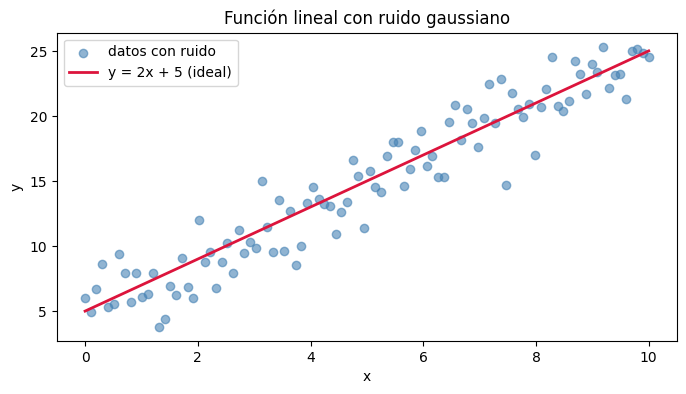

In [27]:
np.random.seed(42)

x = np.linspace(0, 10, 100)

# Función lineal: y = 2x + 5
pendiente = 2
ordenada  = 5
y_ideal   = pendiente * x + ordenada

# Ruido gaussiano: media 0, desvío 2
ruido = np.random.normal(loc=0, scale=2, size=len(x))
y     = y_ideal + ruido

plt.figure(figsize=(8, 4))
plt.scatter(x, y, color='steelblue', alpha=0.6, label='datos con ruido')
plt.plot(x, y_ideal, color='crimson', linewidth=2, label='y = 2x + 5 (ideal)')
plt.title('Función lineal con ruido gaussiano')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

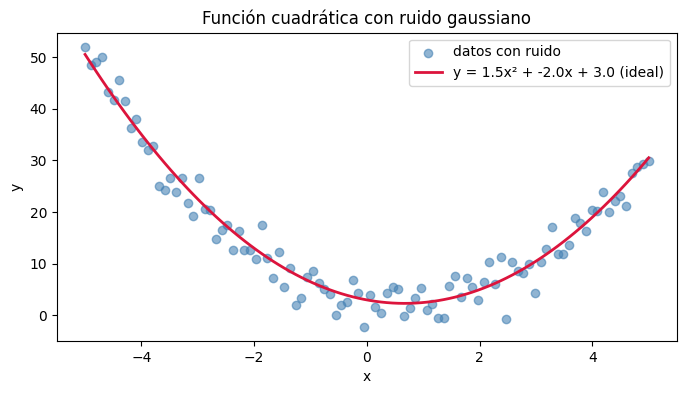

In [29]:
np.random.seed(42)

x = np.linspace(-5, 5, 100)

# Coeficientes de la parábola
a =  1.5
b = -2.0
c =  3.0

y_ideal = a * x**2 + b * x + c

# Ruido gaussiano
ruido = np.random.normal(loc=0, scale=3, size=len(x))
y     = y_ideal + ruido

plt.figure(figsize=(8, 4))
plt.scatter(x, y, color='steelblue', alpha=0.6, label='datos con ruido')
plt.plot(x, y_ideal, color='crimson', linewidth=2, label=f'y = {a}x² + {b}x + {c} (ideal)')
plt.title('Función cuadrática con ruido gaussiano')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

In [30]:
from sklearn.datasets import make_blobs, make_moons, make_circles

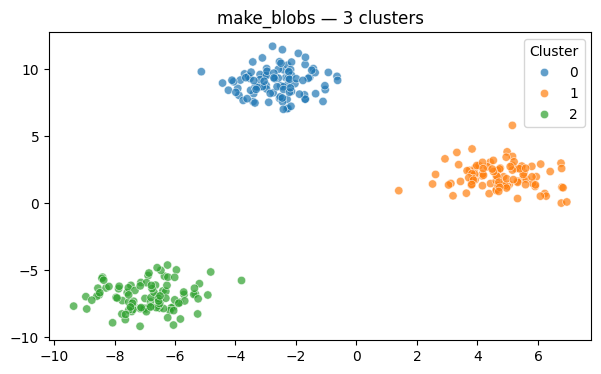

In [32]:
X, y = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

plt.figure(figsize=(7, 4))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette='tab10', alpha=0.7)
plt.title('make_blobs — 3 clusters')
plt.legend(title='Cluster')
plt.show()

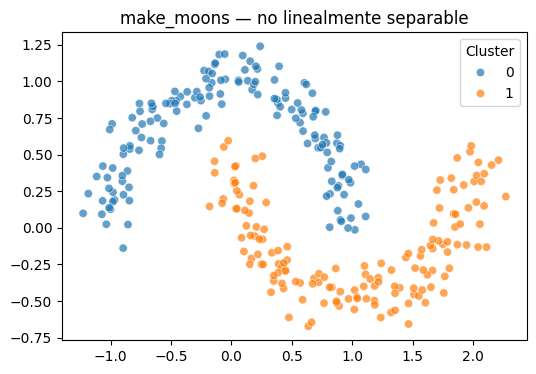

In [33]:
X, y = make_moons(n_samples=300, noise=0.1, random_state=42)

plt.figure(figsize=(6, 4))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette='tab10', alpha=0.7)
plt.title('make_moons — no linealmente separable')
plt.legend(title='Cluster')
plt.show()

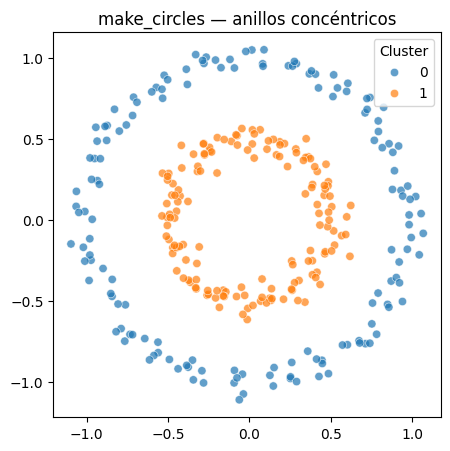

In [ ]:
X, y = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=42)

plt.figure(figsize=(5, 5))
sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette='tab10', alpha=0.7)
plt.title('make_circles — anillos concéntricos')
plt.legend(title='Cluster')
plt.show()

In [35]:
df_circles = pd.DataFrame({
    'x1': X[:, 0],
    'x2': X[:, 1],
    'cluster': y
})

df_circles.head()

,x1,x2,cluster
0,-0.241830,0.425163,1
1,0.209763,-0.489948,1
2,0.427926,0.040112,1
3,0.881626,0.416984,0
4,-0.470089,-0.171297,1
